# 02 · Dataset preparation
**Machine Learning and Data Analytics, Coursework 1 · Student ID: 18503**

This notebook turns the EDA findings into a reproducible preparation pipeline (`src/features.py`) and justifies each step.

| EDA finding | Step taken here |
|---|---|
| Target is zero-inflated and right-skewed | Two targets: `any_fishing` (0/1) and `log_fishing_hours` (for rows with fishing) |
| `hours`, `n_vessels` heavily skewed | `log1p` transform |
| Length, engine power and tonnage correlate at 0.90 to 0.94 | Keep `mean_length_m`, drop the other two |
| Month is cyclic | `sin` and `cos` of month |
| Fishing grounds are tightly clustered in space | Hold out whole 10° × 10° geographic blocks |
| Vessel features are flag × gear averages | Excluded when the task is predicting gear |

In [1]:
import os, sys, json, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src import features as F
from src import plotstyle as P
P.apply()

DATA = ROOT / "data" / "processed" / "fishing_sample.parquet"
FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
MODELS = ROOT / "models"; MODELS.mkdir(exist_ok=True)
SEED = F.SEED
FAST = os.environ.get("CW_FAST") == "1"   # quick smoke test; leave unset for real results

## 1. Load and add targets, blocks and engineered features

In [2]:
raw = F.load_sample(DATA)
df = F.prepare(raw)
print(f"{len(df):,} rows, {df.shape[1]} columns")
new_cols = [c for c in df.columns if c not in raw.columns]
print("New columns:", new_cols)
df[new_cols].head()

319,162 rows, 25 columns
New columns: ['any_fishing', 'log_fishing_hours', 'fishing_share', 'block', 'abs_lat', 'month_sin', 'month_cos', 'log_hours', 'log_n_vessels']


,any_fishing,log_fishing_hours,fishing_share,block,abs_lat,month_sin,month_cos,log_hours,log_n_vessels
0,0,0.000000,0.000000,14004,54.1,-1.000000e+00,-1.836970e-16,0.777029,0.693147
1,0,0.000000,0.000000,8024,6.2,-2.449294e-16,1.000000e+00,3.038562,7.539559
2,1,2.660721,1.000000,12030,35.3,1.000000e+00,6.123234e-17,2.660721,2.833213
3,1,0.695345,0.579473,14018,52.8,-8.660254e-01,5.000000e-01,1.005510,1.791759
4,0,0.000000,0.000000,14018,59.1,-8.660254e-01,5.000000e-01,0.427618,4.077537


## 2. Missing values
The vessel summary columns can contain gaps (some vessel records have no length, engine or tonnage). They are **not** filled here: a median imputer sits inside the model pipeline and is fitted on the training rows only, so no test information leaks into the fill values.

In [3]:
miss = df[F.VESSEL_COLS].isna().mean().mul(100).round(2).to_frame("% missing")
miss

,% missing
n_vessels,0.00
mean_length_m,0.00
mean_engine_kw,0.00
mean_tonnage_gt,0.00
share_self_reported,0.00
mean_class_score,0.38


## 3. Transformations
Skewness before and after `log1p`. A value near 0 means roughly symmetric.

In [4]:
sk = pd.DataFrame({
    "skew_raw": df[["hours", "n_vessels"]].skew(),
    "skew_log1p": pd.Series({"hours": df["log_hours"].skew(), "n_vessels": df["log_n_vessels"].skew()}),
}).round(2)
sk

,skew_raw,skew_log1p
hours,282.93,1.74
n_vessels,8.19,0.20


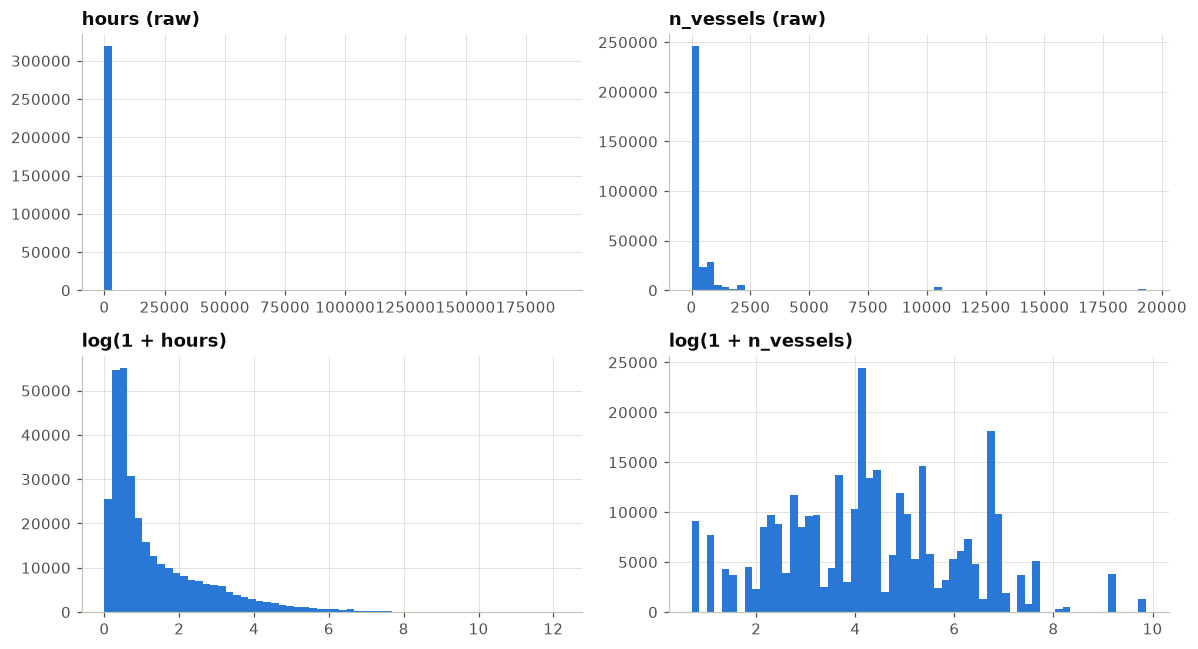

In [5]:
fig, ax = plt.subplots(2, 2, figsize=(11, 6))
for j, (raw_c, log_c) in enumerate([("hours", "log_hours"), ("n_vessels", "log_n_vessels")]):
    ax[0, j].hist(df[raw_c], bins=60, color=P.BLUE); ax[0, j].set_title(f"{raw_c} (raw)")
    ax[1, j].hist(df[log_c], bins=60, color=P.BLUE); ax[1, j].set_title(f"log(1 + {raw_c})")
fig.tight_layout(); P.save(fig, FIG / "11_log_transforms.png")

## 4. Redundant features
After dropping `mean_engine_kw` and `mean_tonnage_gt`, check that no remaining pair is highly correlated.

In [6]:
kept = ["mean_length_m", "log_n_vessels", "share_self_reported", "mean_class_score",
        "log_hours", "mmsi_present", "abs_lat"]
c = df[kept].corr(method="spearman")
pairs = (c.where(np.triu(np.ones(c.shape), 1).astype(bool)).stack().rename("rho")
           .reset_index().rename(columns={"level_0": "a", "level_1": "b"}))
pairs["abs_rho"] = pairs["rho"].abs()
pairs.sort_values("abs_rho", ascending=False).head(8).round(2)

,a,b,rho,abs_rho
33,log_hours,mmsi_present,0.56,0.56
4,mean_length_m,log_hours,-0.26,0.26
12,log_n_vessels,mmsi_present,0.26,0.26
10,log_n_vessels,mean_class_score,0.21,0.21
6,mean_length_m,abs_lat,-0.20,0.20
20,share_self_reported,abs_lat,0.20,0.20
27,mean_class_score,abs_lat,-0.20,0.20
11,log_n_vessels,log_hours,0.17,0.17


## 5. Train and test split by geographic block
A random row split would put neighbouring cells of the same fishing ground in both sets, so the test score would reward memorising places. Instead whole 10° × 10° blocks go to either train or test (20% of blocks held out). The test set is created here only to check the split. **No model in notebook 03 sees it**; it is used once, in notebook 04.

In [7]:
train_idx, test_idx = F.geo_split(df)
train, test = df.iloc[train_idx], df.iloc[test_idx]
print(f"Blocks: {df['block'].nunique()} total | train {train['block'].nunique()} | test {test['block'].nunique()}")
print(f"Rows  : train {len(train):,} ({len(train)/len(df):.0%}) | test {len(test):,} ({len(test)/len(df):.0%})")
print("Shared blocks between train and test:", len(set(train['block']) & set(test['block'])))

Blocks: 471 total | train 376 | test 95
Rows  : train 237,895 (75%) | test 81,267 (25%)
Shared blocks between train and test: 0


In [8]:
cmp = pd.DataFrame({
    "train": [train["any_fishing"].mean(), train.loc[train.any_fishing == 1, "log_fishing_hours"].mean()],
    "test":  [test["any_fishing"].mean(),  test.loc[test.any_fishing == 1, "log_fishing_hours"].mean()],
}, index=["share with fishing", "mean log hours (fishing rows)"]).round(3)
cmp

,train,test
share with fishing,0.309,0.343
mean log hours (fishing rows),1.882,1.822


In [9]:
gear_mix = pd.concat([train["geartype"].value_counts(normalize=True).rename("train"),
                      test["geartype"].value_counts(normalize=True).rename("test")], axis=1).mul(100).round(1)
gear_mix

,train,test
geartype,,
squid_jigger,7.5,2.6
drifting_longlines,6.8,4.7
pots_and_traps,6.7,4.9
pole_and_line,6.7,5.1
tuna_purse_seines,6.7,5.1
fishing,6.7,5.1
fixed_gear,6.5,5.6
purse_seines,6.4,5.7
set_longlines,6.3,6.1


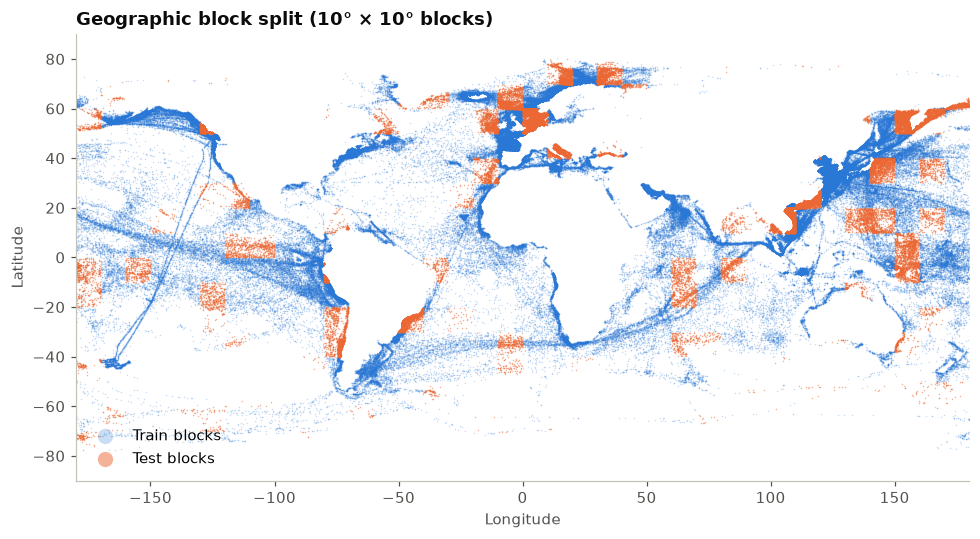

In [10]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.scatter(train["cell_ll_lon"], train["cell_ll_lat"], s=1, color=P.BLUE, alpha=0.25, linewidths=0, label="Train blocks")
ax.scatter(test["cell_ll_lon"], test["cell_ll_lat"], s=1, color=P.ORANGE, alpha=0.5, linewidths=0, label="Test blocks")
ax.set_xlim(-180, 180); ax.set_ylim(-90, 90); ax.set_aspect("equal"); ax.grid(False)
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude"); ax.set_title("Geographic block split (10° × 10° blocks)")
lg = ax.legend(markerscale=10, frameon=False, loc="lower left")
fig.tight_layout(); P.save(fig, FIG / "12_block_split.png")

## 6. Feature sets
Two feature sets are compared in notebook 03:

* **Set A (deployable):** location, season, gear, flag and vessel summaries. Everything a user can supply in the app.
* **Set B (A + activity):** adds `log_hours` and `mmsi_present`, which describe total vessel activity in the same cell and month. `hours` includes the fishing time, so B answers an easier question and is reported as an upper bound.

In [11]:
A = F.feature_sets(with_activity=False)
B = F.feature_sets(with_activity=True)
pd.DataFrame({"Set A": [", ".join(A["num"]), ", ".join(A["cat"])],
              "Set B": [", ".join(B["num"]), ", ".join(B["cat"])]}, index=["numeric", "categorical"]).T

,numeric,categorical
Set A,"cell_ll_lat, cell_ll_lon, abs_lat, month_sin, ...","flag, geartype"
Set B,"cell_ll_lat, cell_ll_lon, abs_lat, month_sin, ...","flag, geartype"


In [12]:
# Fit the preprocessor on TRAIN only, then transform both sets
cols = A["num"] + A["cat"]
pre = F.make_preprocessor(A["num"], A["cat"])
Xtr = pre.fit_transform(train[cols]); Xte = pre.transform(test[cols])
names = pre.get_feature_names_out()
print("Train matrix:", Xtr.shape, "| Test matrix:", Xte.shape, "| NaNs left:", int(np.isnan(Xtr).sum() + np.isnan(Xte).sum()))
print("Numeric columns on train after scaling: mean ~0, std ~1 ->",
      np.round(Xtr[:, :len(A['num'])].mean(), 3), np.round(Xtr[:, :len(A['num'])].std(), 3))
print("Same columns on test (scaled with TRAIN statistics): mean",
      np.round(Xte[:, :len(A['num'])].mean(), 3))
print("One-hot columns:", len(names) - len(A["num"]), "(flags under 1% of rows are pooled as 'infrequent')")

Train matrix: (237895, 44) | Test matrix: (81267, 44) | NaNs left: 0
Numeric columns on train after scaling: mean ~0, std ~1 -> 0.0 1.0
Same columns on test (scaled with TRAIN statistics): mean 0.039
One-hot columns: 35 (flags under 1% of rows are pooled as 'infrequent')


## 7. Summary of preparation decisions
Use this list as the backbone of the "Dataset preparation" section of the report.

1. **Targets:** `any_fishing = fishing_hours > 0`; `log_fishing_hours = log1p(fishing_hours)` modelled only where fishing occurs.
2. **Missing values:** median imputation inside the pipeline, fitted on training rows only.
3. **Skew:** `log1p` for `hours` and `n_vessels`.
4. **Redundancy:** drop `mean_engine_kw` and `mean_tonnage_gt` (correlation 0.90 or more with length).
5. **Cyclic month:** `sin` and `cos`.
6. **Categoricals:** one-hot with rare flags pooled; `UNKNOWN` flags kept as their own levels.
7. **Scaling:** standardisation for linear models (harmless for trees).
8. **Split:** whole 10° × 10° blocks, 80% train and 20% test; all tuning uses block-grouped cross-validation inside the training set.
9. **Leakage controls:** vessel summaries removed for gear classification; `hours` tested separately as an upper bound.